Preparacion 

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

DATOS = Path("../data/PlantVillage")

una función que recibe la ruta de una foto y devuelve sus características:

In [2]:
def extraer_caracteristicas(ruta):
    matriz= np.array(Image.open(ruta).convert("RGB"))
    promedio = matriz.mean(axis=(0,1))#cuanto vale en promedio cada canal de color
    desvio = matriz.std(axis=(0,1)) #cuanto varia cada canal de color 
    return {
        "promedio_rojo": promedio[0],
        "promedio_verde": promedio[1],
        "promedio_azul": promedio[2],
        "desvio_rojo": desvio[0],
        "desvio_verde": desvio[1],
        "desvio_azul": desvio[2]

    }

def crea una función: un bloque de código con nombre que podés usar muchas veces.
axis=(0, 1) significa “promediá a lo alto y a lo ancho”, así queda un solo número por canal de color.
El desvío mide cuánto cambian los valores dentro de la foto. Una hoja lisa y pareja tiene desvío bajo; una con manchas, alto.

Tiene que dar rojo_prom cerca de 97.6 y verde_prom cerca de 109.0, con el verde como el más alto.

In [3]:
carpeta= DATOS / "Tomato_Late_blight"
prueba= list(carpeta.iterdir())[0]
extraer_caracteristicas(prueba)

{'promedio_rojo': np.float64(125.44126892089844),
 'promedio_verde': np.float64(117.66810607910156),
 'promedio_azul': np.float64(101.712890625),
 'desvio_rojo': np.float64(63.149606264542484),
 'desvio_verde': np.float64(54.541259543078674),
 'desvio_azul': np.float64(59.554949062653264)}

ruta.suffix es la extensión del archivo, por ejemplo .JPG.
.lower() la pasa a minúsculas, así .JPG y .jpg cuentan como lo mismo.
in EXTENSIONES pregunta si está en la lista de válidas. El archivo basura no tiene extensión, así que queda afuera.

In [4]:
EXTENSIONES= [".jpg", ".jpeg", ".png"]
filas=[]
for carpeta in DATOS.iterdir():
    if carpeta.name.startswith("Tomato"):
        for ruta in carpeta.iterdir():
            if ruta.suffix.lower() in EXTENSIONES:
                fila=extraer_caracteristicas(ruta)
                fila["clase"]= carpeta.name
                filas.append(fila)
tabla= pd.DataFrame(filas)
tabla.shape            

(16011, 7)

Ya van tres sorpresas en estos datos: la carpeta duplicada, el desbalance y ahora un archivo basura. Es lo normal. Se suele decir que un científico de datos pasa la mayor parte del tiempo limpiando datos y no entrenando modelos, y lo estás comprobando en tu propio proyecto.

Pregunta: ¿cuántas filas hay de cada clase?

tabla["clase"] selecciona la columna clase.
.value_counts() cuenta cuántas veces aparece cada valor.
Sirve como control: cada fila es una foto, así que el resultado tiene que coincidir con la cantidad de fotos de cada carpeta. Si apareciera una sola clase, o números raros, sabríamos que la tabla se armó mal, como pasó con el error de carpetas.

In [5]:
tabla["clase"].value_counts()

clase
Tomato__Tomato_YellowLeaf__Curl_Virus          3208
Tomato_Bacterial_spot                          2127
Tomato_Late_blight                             1909
Tomato_Septoria_leaf_spot                      1771
Tomato_Spider_mites_Two_spotted_spider_mite    1676
Tomato_healthy                                 1591
Tomato__Target_Spot                            1404
Tomato_Early_blight                            1000
Tomato_Leaf_Mold                                952
Tomato__Tomato_mosaic_virus                     373
Name: count, dtype: int64

tabla.groupby("clase")["promedio_verde"].mean().sort_values()
Pregunta: ¿cuánto verde tienen, en promedio, las fotos de cada clase?

el resultado sería enferma 70 y sana 115: un número por clase.

In [6]:
tabla.groupby("clase")["promedio_verde"].mean().sort_values()

clase
Tomato_Bacterial_spot                          108.668254
Tomato_Early_blight                            113.035147
Tomato_Late_blight                             115.166323
Tomato__Tomato_mosaic_virus                    116.636025
Tomato_Leaf_Mold                               117.227910
Tomato_healthy                                 118.613556
Tomato_Spider_mites_Two_spotted_spider_mite    119.651030
Tomato__Target_Spot                            120.036321
Tomato__Tomato_YellowLeaf__Curl_Virus          120.171928
Tomato_Septoria_leaf_spot                      133.070353
Name: promedio_verde, dtype: float64

Paso 7: entrenar tu primer modelo

Antes del código, la idea más importante de todo machine learning: nunca se evalúa un modelo con los mismos datos con los que aprendió. Sería como tomar un examen con las mismas preguntas que se usaron para estudiar: no sabés si el alumno entendió o memorizó. Por eso se divide la tabla en dos:

Entrenamiento (80%): el modelo aprende de estas fotos.
Prueba (20%): fotos que el modelo nunca vio y que usamos para ponerle nota.

separar features y target:

In [7]:
x=tabla.drop(columns="clase")# las 6 columnas de números
y=tabla["clase"]# lo que queremos predecir

dividir en entrenamiento y prueba

test_size=0.2 reserva el 20% para la prueba.
random_state=42 fija el sorteo, para que el resultado sea el mismo cada vez que lo ejecutes.
stratify=y mantiene la proporción de cada clase en las dos partes, importante por el desbalance que encontraste.
Tiene que mostrar 12808 3203.



In [8]:
from sklearn.model_selection import train_test_split
x_entreno, x_prueba, y_entreno, y_prueba = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(len(x_entreno),len(x_prueba))

12808 3203


entrenar y evaluar

Reconocés el patrón de la clase 1: fit para aprender y predict para usar lo aprendido. El modelo es un Random Forest (bosque aleatorio): cientos de árboles de decisión que votan entre todos. Más adelante te explico cómo funciona por dentro.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

modelo= RandomForestClassifier(random_state=42)
modelo.fit(x_entreno, y_entreno) #aprendemos de los datos de entrenamiento

predicciones=modelo.predict(x_prueba) #predecimos con los datos de prueba que nunca vio
accuracy_score(y_prueba,predicciones) #porcentajes de aciertos 

0.7165157664689353

Qué significa exactamente 0.72
Ese número se llama exactitud (accuracy) y es la proporción de aciertos sobre el total de fotos de prueba:

0.72 equivale a 72%.
El conjunto de prueba tenía 3.203 fotos que el modelo nunca había visto.
Acertó la enfermedad en unas 2.300 y se equivocó en unas 900.
La escala va de 0 (no acierta ninguna) a 1 (acierta todas). Una respuesta completa sería: “el modelo clasifica bien 72 de cada 100 hojas que nunca vio”.

In [10]:
from sklearn.metrics import classification_report

print(classification_report(y_prueba, predicciones))

                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot       0.76      0.79      0.78       426
                        Tomato_Early_blight       0.49      0.34      0.40       200
                         Tomato_Late_blight       0.69      0.63      0.66       382
                           Tomato_Leaf_Mold       0.76      0.59      0.67       190
                  Tomato_Septoria_leaf_spot       0.77      0.74      0.75       354
Tomato_Spider_mites_Two_spotted_spider_mite       0.62      0.67      0.64       335
                        Tomato__Target_Spot       0.58      0.64      0.61       281
      Tomato__Tomato_YellowLeaf__Curl_Virus       0.77      0.85      0.81       642
                Tomato__Tomato_mosaic_virus       0.73      0.53      0.62        75
                             Tomato_healthy       0.82      0.89      0.86       318

                                   accuracy                    

El modelo reconoce 89 de cada 100 hojas sanas, pero solo 34 de cada 100 con tizón temprano. Las otras 66 las confunde con otra cosa. El 72% general escondía esta diferencia enorme.

En tu fila, 0.49 0.34 0.40 200, los cuatro números son:

precision 0,49: cuando el modelo dice “tizón temprano”, acierta la mitad de las veces.
recall 0,34: de las hojas que realmente lo tienen, detecta el 34%.
f1-score 0,40: un resumen de los dos anteriores.
support 200: cuántas fotos de esa clase había en la prueba.
Pregunta 3: se cumplió a medias
Dijiste que sí se cumplió, y en parte es cierto: el virus del mosaico, la clase con menos fotos, tiene recall 0,53, bastante por debajo del promedio.

Pero la peor clase no es esa. Es el tizón temprano, que tiene 1.000 fotos, casi el triple. Así que el desbalance influye, pero no explica todo. La otra causa es más simple: nuestras 6 características solo miden color, y el tizón temprano tiene colores muy parecidos a los de otras enfermedades. Por color no se puede distinguir; hace falta mirar la forma de las manchas.

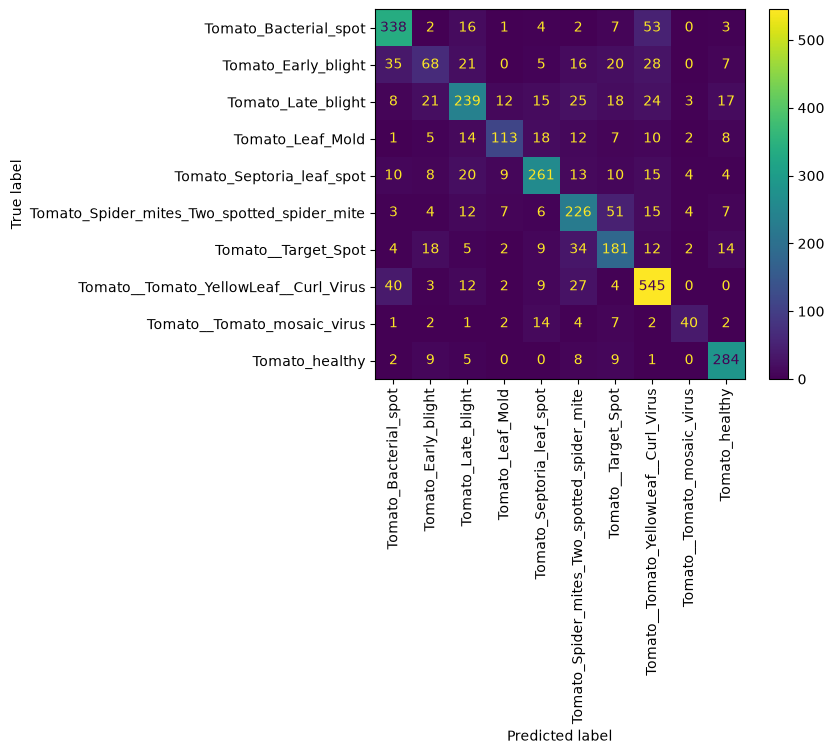

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_prueba, predicciones, xticks_rotation="vertical"
)

In [12]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(y_prueba, predicciones, labels=modelo.classes_)
confusion = pd.DataFrame(matriz, index=modelo.classes_, columns=modelo.classes_)

confusion_matrix calcula los mismos números del gráfico, pero como datos.
modelo.classes_ es la lista de nombres de las clases, en el orden que usa el modelo.
index son los nombres de las filas (la clase real) y columns los de las columnas (lo que dijo el modelo)

In [13]:
confusion.loc["Tomato__Tomato_mosaic_virus"].sort_values(ascending=False)

Tomato__Tomato_mosaic_virus                    40
Tomato_Septoria_leaf_spot                      14
Tomato__Target_Spot                             7
Tomato_Spider_mites_Two_spotted_spider_mite     4
Tomato__Tomato_YellowLeaf__Curl_Virus           2
Tomato_Early_blight                             2
Tomato_healthy                                  2
Tomato_Leaf_Mold                                2
Tomato_Bacterial_spot                           1
Tomato_Late_blight                              1
Name: Tomato__Tomato_mosaic_virus, dtype: int64

Text(0, 0.5, 'Clase real')

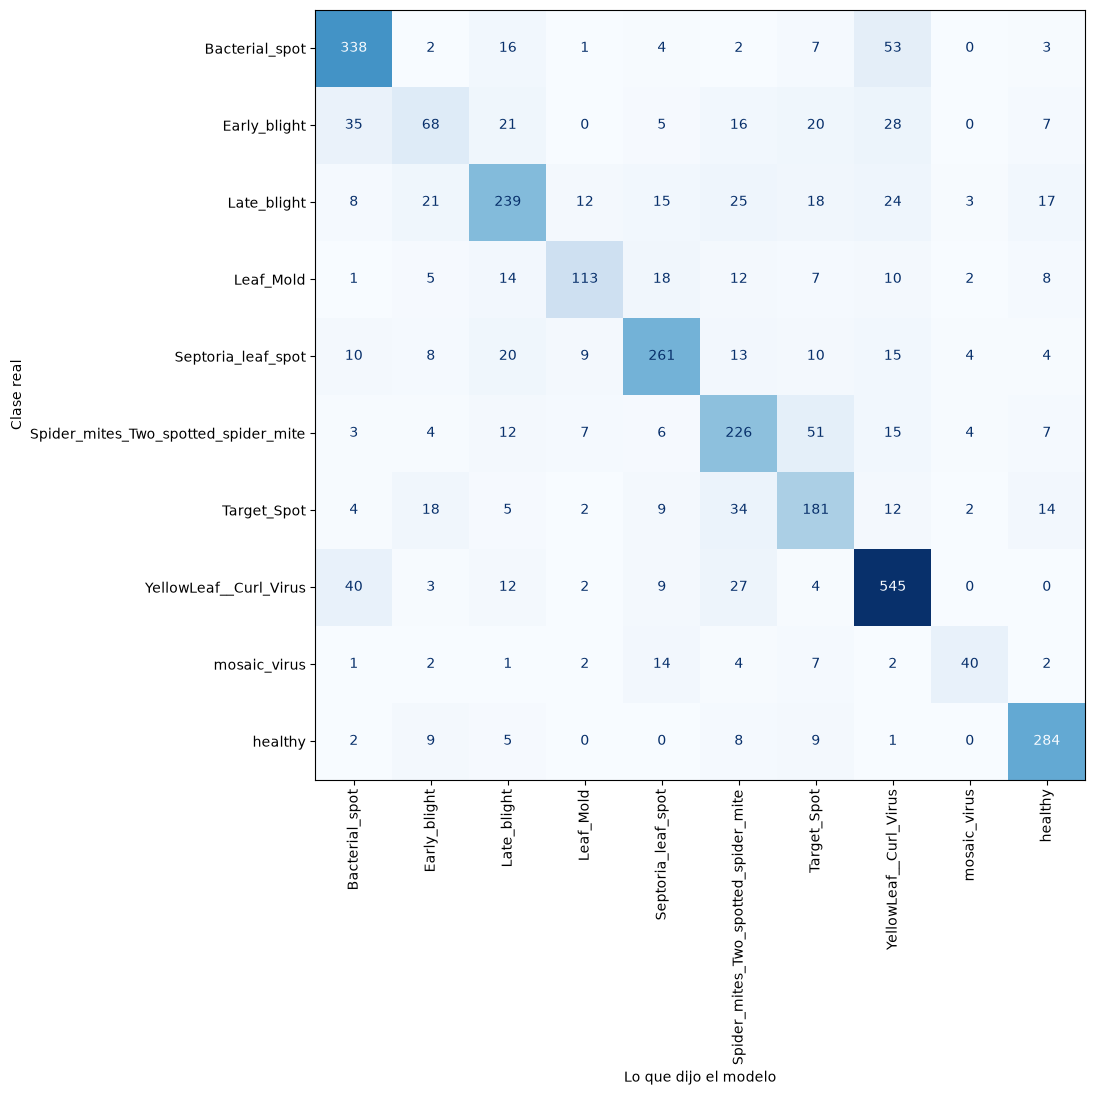

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

nombres = [c.replace("Tomato__Tomato_", "").replace("Tomato__", "").replace("Tomato_", "")
           for c in modelo.classes_]

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    y_prueba, predicciones,
    labels=modelo.classes_, display_labels=nombres,
    xticks_rotation="vertical", cmap="Blues", colorbar=False, ax=ax,
)
ax.set_xlabel("Lo que dijo el modelo")
ax.set_ylabel("Clase real")

los cuatro modelos en un diccionario:

Random Forest=	Muchos árboles de decisión independientes que votan
Gradient Boosting=	Árboles en cadena, donde cada uno corrige los errores del anterior
K vecinos	= Busca las fotos más parecidas y copia su clase
Regresión logística= 	Separa las clases con fronteras rectas

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler

modelos ={
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "k vecinos": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Regresion Logistica": make_pipeline (StandardScaler(), LogisticRegression(max_iter=2000)),

}

StandardScaler pone todas las columnas en la misma escala. Los dos últimos modelos lo necesitan porque trabajan con distancias; los que usan árboles no. make_pipeline encadena los dos pasos: primero escalar, después el modelo.

modelos.items() entrega cada par, nombre y modelo, de a uno.
.score() hace predict y calcula la exactitud en un solo paso.
Usé la variable m y no modelo a propósito, para no pisar tu Random Forest original, que usan las celdas de la matriz de confusión.

In [21]:
resultados =[]
for nombre, m in modelos.items():
    m.fit(x_entreno, y_entreno)
    exactitud = m.score(x_prueba, y_prueba)
    resultados.append({"modelo": nombre, "exactitud": exactitud})
comparacion = pd.DataFrame(resultados).sort_values("exactitud", ascending=False)
comparacion     


,modelo,exactitud
1,Gradient Boosting,0.725882
0,Random Forest,0.716516
2,k vecinos,0.715267
3,Regresion Logistica,0.528567


<Axes: title={'center': 'comparacion de exactitude de modelos'}, ylabel='modelo'>

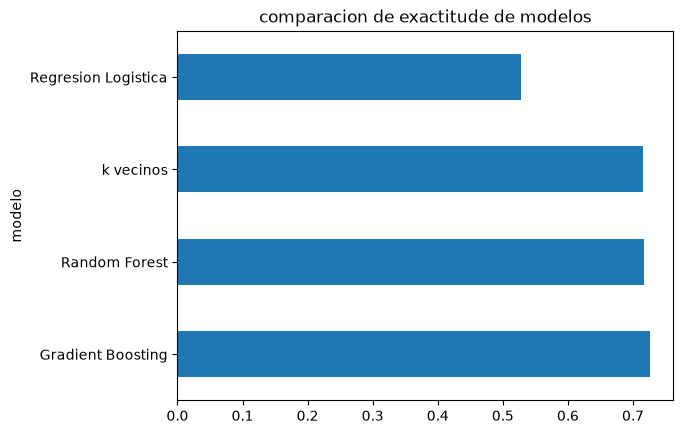

In [23]:
comparacion.plot.barh(x="modelo", y="exactitud", legend=False, title="comparacion de exactitude de modelos")



COMO SE VE EN EL GRAFICO PODEMOS VERO QUE LOS TRES MODELOS TRABAJAN PARECIDOS POR QUE NO HAY SUFICIENTE INFORMACION , SOLAMENTE LOS NUMEROS DE LOS COLORES 6